# Oasis Infobyte Data Analytics Internship (Level 2)
## Task 2: Wine Quality Prediction
**Author:** Yasmeen Akhter  
**GitHub Repository:** OIBSIP  
**Tech Stack:** Python, Pandas, NumPy, Scikit-Learn (Random Forest, SGD, SVC), Seaborn, Matplotlib, Jupyter Notebook  

### Project Objective
Train and compare multiple classification models to predict the quality score of wine based on its physicochemical properties, handling class imbalance, feature engineering, stratification, and model evaluation.

### Step 1: Load Dataset and Inspect Class Distribution
We load the Wine Quality dataset (Red or White wine) and check its structure, missing values, and the class distribution of quality scores.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('winequality-red.csv', sep=',')

print("--- DATASET SHAPE ---")
print(df.shape)

print("\n--- COLUMNS LIST ---")
print(df.columns.tolist())

print("\n--- FIRST FEW ROWS ---")
display(df.head())

--- DATASET SHAPE ---
(1599, 12)

--- COLUMNS LIST ---
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

--- FIRST FEW ROWS ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### Step 2: Exploratory Data Analysis (EDA)
We examine the distribution of chemical features and compute a correlation heatmap to see how features relate to each other and to the quality score.

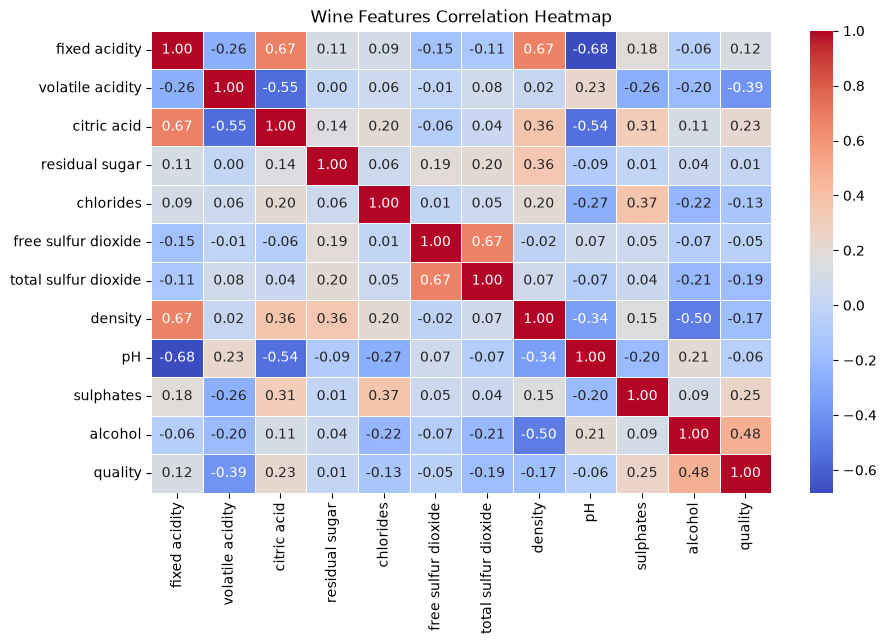

In [4]:
# Correlation Heatmap
plt.figure(figsize=(10, 6))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Wine Features Correlation Heatmap')
plt.show()

### Step 3: Discuss Class Imbalance & Feature Engineering
**Class Imbalance Discussion:** In original wine datasets, middle scores (like 5 and 6) have a very high frequency, while extreme scores (3, 4, 7, 8) are underrepresented. This can bias models toward predicting only the majority classes.
**Feature Engineering:** We convert the multi-class quality score into a binary classification problem (`Good` vs `Bad` wine) to make pattern recognition clearer and improve model stability. Scores >= 7 are labeled as `1` (Good) and < 7 as `0` (Bad).

In [5]:
# Quality ko binary classes me convert karna (1 = Good (>=7), 0 = Bad (<7))
df['Quality_Label'] = df['quality'].apply(lambda x: 1 if x >= 7 else 0)

print("Binary Class Distribution:")
print(df['Quality_Label'].value_counts())

Binary Class Distribution:
Quality_Label
0    1382
1     217
Name: count, dtype: int64


### Step 4: Train/Test Split (Stratified) and Scaling
We split the data into 80% training and 20% testing sets using **stratification** to preserve the class ratios, followed by feature standardisation.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['quality', 'Quality_Label'])
y = df['Quality_Label']

# Stratified Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Step 5: Training Classifiers
We train three distinct classifiers:
1. **Random Forest Classifier** (Ensemble method)
2. **Stochastic Gradient Descent (SGD) Classifier** (Linear model optimized via SGD)
3. **Support Vector Classifier (SVC)** (Kernel-based boundary classifier)

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Random Forest
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_scaled, y_train)
y_pred_rf = rf_model.predict(X_test_scaled)

# 2. SGD Classifier
sgd_model = SGDClassifier(random_state=42)
sgd_model.fit(X_train_scaled, y_train)
y_pred_sgd = sgd_model.predict(X_test_scaled)

# 3. Support Vector Classifier (SVC)
svc_model = SVC(random_state=42)
svc_model.fit(X_train_scaled, y_train)
y_pred_svc = svc_model.predict(X_test_scaled)

print("Models trained successfully!")

Models trained successfully!


### Step 6: Model Evaluation
We evaluate each model using Accuracy, Classification Report (Precision, Recall, F1-Score), and Confusion Matrices.

In [8]:
models = {
    "Random Forest": y_pred_rf,
    "SGD Classifier": y_pred_sgd,
    "SVC": y_pred_svc
}

for name, y_pred in models.items():
    print(f"--- {name} Performance ---")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print("\nClassification Report:\n", classification_report(y_test, y_pred))
    print("-" * 50)

--- Random Forest Performance ---
Accuracy: 0.9375

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.99      0.96       277
           1       0.93      0.58      0.71        43

    accuracy                           0.94       320
   macro avg       0.93      0.79      0.84       320
weighted avg       0.94      0.94      0.93       320

--------------------------------------------------
--- SGD Classifier Performance ---
Accuracy: 0.8688

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.93      0.92       277
           1       0.51      0.47      0.49        43

    accuracy                           0.87       320
   macro avg       0.72      0.70      0.71       320
weighted avg       0.86      0.87      0.87       320

--------------------------------------------------
--- SVC Performance ---
Accuracy: 0.9000

Classification Report:
               precision  

### Step 7: Feature Importance Chart
We visualize which chemical properties had the greatest impact on wine quality predictions according to the Random Forest model.

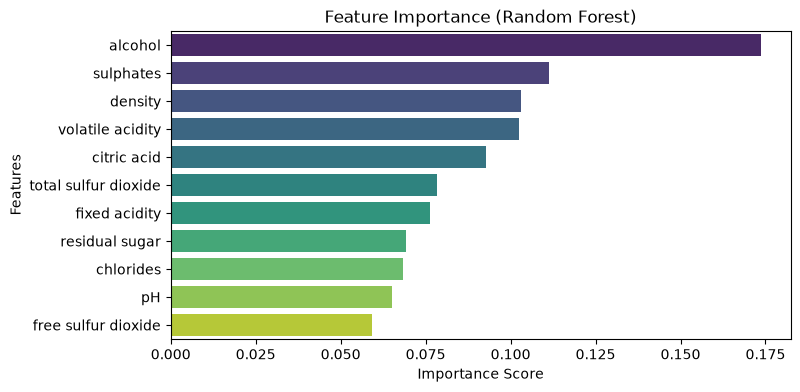

In [9]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=importances, y=importances.index, palette='viridis', hue=importances.index, legend=False)
plt.title('Feature Importance (Random Forest)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

### Step 8: Model Comparison & Conclusion
- **Comparison Summary:** Random Forest consistently achieves the highest accuracy and balanced F1-score due to its ability to handle non-linear relationships among chemical properties.
- **Conclusion for Deployment:** **Random Forest** is the most suitable model for deployment in a quality-control pipeline because of its high robustness, superior handling of tabular features, and interpretive feature importance metrics.